Universidad Franz Tamayo  
Carrera de Ingeniería de Sistemas  
Asignatura: MINERÍA DE DATOS

**Proyecto de Minería de Datos: Predicción de complicaciones médicas en pacientes**

- Grupo:KRISKAO
- Docente: Ing. Enrique Alejandro Laurel Cossio 


**Integrantes:**
- Alejandro Cesar Acho Huallpa
- Jorge Armando Coquendo Amba
- Shaden Ahira Cruz Condori
- Jose Angel Escarzo Mamani
- Jhonatan Oraque

PUNTO 1 — Definición del problema y variable objetivo

**1. ¿Qué problema concreto aborda su proyecto?**

R.

- **Problema:** el 87.82% de los pacientes registrados presenta alguna complicación médica.
- **Decisión que apoya:** identificar de forma temprana a los pacientes con mayor riesgo de complicación para priorizarlos en un programa de prevención.
- **Criterio de éxito:** reducir la prevalencia de complicaciones mediante intervención oportuna apoyada en el modelo.

**2. ¿Cuál es la métrica principal del proyecto y cómo se calcula?**

R.

- **Métrica principal:** Prevalencia de complicaciones.
- **Fórmula:** Prevalencia = (Pacientes con complicación / Total pacientes) x 100
- **Valor observado:** 87.82% (8,782 de 10,000 pacientes).
- **Tipo:** métrica de negocio (no de desempeño del modelo).

PUNTO 2 — Preparación de los datos

## Librerías

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score,
                             f1_score, roc_auc_score)

## Carga de datos

In [3]:
# El Excel debe estar en la misma carpeta que este notebook
df_original = pd.read_excel("base_de_datos_medicina_complicaciones_modificada.xlsx")
df = df_original.copy()

print("Registros (filas):", df.shape[0])
print("Variables (columnas):", df.shape[1])
df.head(3)

Registros (filas): 10000
Variables (columnas): 41


,NRO_REGISTRO,CI_PACIENTE,NOMBRE,APELLIDO1,APELLIDO2,SEXO,FECHA_NACIMIENTO,EDAD,ESTADO_CIVIL,OCUPACION,...,HEMOGLOBINA,CREATININA,RESULTADO_LABORATORIO,TRATAMIENTO,DIAS_HOSPITALIZACION,MEDIDA_PREVENCION,NUMERO_CONTROLES,ESTADO_PACIENTE,COMPLICACIONES,OBSERVACIONES
0,BNS-2023-000001,3341057 CB,Alex,Rivera,Herrera,M,10/08/1986,40,Soltero/a,Comerciante,...,10.2,3.89,Pendiente,Consulta Externa,0,Radiografia de Torax,12,Estable,Infeccion Nosocomial,Registro generado automaticamente por el Banco...
1,BNS-2024-000002,2166941 LP,Ofelia,Miranda,Reyes,F,27/02/1992,34,Divorciado/a,Doctor/a,...,11.8,4.95,Pendiente,Resonancia Magnetica,0,Examen de Orina,4,Estable,Embolia,Registro generado automaticamente por el Banco...
2,BNS-2024-000003,5443951 SC,Daniela,Arce,Martinez,F,08/01/2001,25,Soltero/a,Peluquero,...,10.5,2.90,Normal,Terapia Intensiva,14,Desparasitacion Semestral,4,Estable,Reaccion Adversa,Registro generado automaticamente por el Banco...


**3. ¿Cuál es la unidad de análisis y cuántos registros tiene el conjunto?**

In [4]:
print("Registros (filas):", df.shape[0])
print("Variables (columnas):", df.shape[1])
print()
print("Tipos de variables:")
print(df.dtypes.value_counts())
print()
print("NRO_REGISTRO únicos:", df["NRO_REGISTRO"].nunique())
print("CI_PACIENTE únicos:", df["CI_PACIENTE"].nunique())

Registros (filas): 10000
Variables (columnas): 41

Tipos de variables:
object     27
int64       8
float64     6
Name: count, dtype: int64

NRO_REGISTRO únicos: 10000
CI_PACIENTE únicos: 10000


R.

- **Unidad de análisis:** el paciente. Cada fila representa el registro de un paciente.
- **Origen:** archivo Excel con datos médicos de pacientes.
- **Registros:** 10,000. **Variables:** 41 columnas originales.
- **Sin filtros:** se usaron los 10,000 registros completos.

**4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron?**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NRO_REGISTRO           10000 non-null  object 
 1   CI_PACIENTE            10000 non-null  object 
 2   NOMBRE                 10000 non-null  object 
 3   APELLIDO1              10000 non-null  object 
 4   APELLIDO2              10000 non-null  object 
 5   SEXO                   10000 non-null  object 
 6   FECHA_NACIMIENTO       10000 non-null  object 
 7   EDAD                   10000 non-null  int64  
 8   ESTADO_CIVIL           10000 non-null  object 
 9   OCUPACION              10000 non-null  object 
 10  NIVEL_EDUCATIVO        10000 non-null  object 
 11  NIVEL_SOCIOECONOMICO   10000 non-null  object 
 12  DEPARTAMENTO           10000 non-null  object 
 13  CAPITAL_DEPTO          10000 non-null  object 
 14  DIRECCION              10000 non-null  object 
 15  TEL

In [6]:
df.describe()

,EDAD,TELEFONO,PESO_KG,ESTATURA_CM,IMC,FRECUENCIA_CARDIACA,TEMPERATURA_C,GLUCEMIA,COLESTEROL_TOTAL,TRIGLICERIDOS,HEMOGLOBINA,CREATININA,DIAS_HOSPITALIZACION,NUMERO_CONTROLES
count,10000.000000,1.000000e+04,10000.000000,10000.000000,9918.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,46.936200,7.548072e+07,91.570390,145.582480,51.425711,84.857200,38.012810,180.301300,199.838900,224.719900,13.023410,2.649961,1.794100,6.001700
std,27.547588,2.594845e+06,33.485332,34.600805,39.324128,20.294507,1.449198,69.114544,58.439698,101.269021,2.896742,1.354487,5.810911,3.765251
min,0.000000,7.100100e+07,2.600000,45.300000,0.700000,50.000000,35.500000,60.000000,100.000000,50.000000,8.000000,0.300000,0.000000,0.000000
25%,23.000000,7.324466e+07,64.475000,120.800000,28.000000,67.000000,36.800000,121.000000,149.000000,136.000000,10.500000,1.500000,0.000000,3.000000
50%,47.000000,7.541180e+07,92.000000,147.400000,41.000000,85.000000,38.000000,181.000000,200.000000,225.000000,13.100000,2.630000,0.000000,6.000000
75%,71.000000,7.774810e+07,119.200000,174.125000,62.775000,102.250000,39.300000,239.000000,251.000000,312.000000,15.600000,3.820000,0.000000,9.000000
max,95.000000,7.999966e+07,150.000000,200.000000,418.000000,120.000000,40.500000,300.000000,300.000000,400.000000,18.000000,5.000000,30.000000,12.000000


R.

- **Valores faltantes:** solo IMC con 82 faltantes (0.82%). Las otras 40 columnas completas.
- **Duplicados:** no hay. Los 10,000 NRO_REGISTRO y CI_PACIENTE son únicos.
- **Preparación aplicada:**
  1. Se imputó IMC con la mediana.
  2. Se creó variable objetivo binaria TARGET_COMPLICACION.
  3. Se convirtieron SEXO y DEPARTAMENTO a variables dummy.
  4. Se dividió en entrenamiento (80%) y prueba (20%) con estratificación.

In [7]:
# Imputar IMC con la mediana
df["IMC"].fillna(df["IMC"].median(), inplace=True)
print("Faltantes IMC después de imputar:", df["IMC"].isnull().sum())

# Variable objetivo binaria
df["TARGET_COMPLICACION"] = (df["COMPLICACIONES"] != "Ninguna").astype(int)
con_complicacion = df["TARGET_COMPLICACION"].sum()
total = df.shape[0]
print(f"Pacientes con complicación: {con_complicacion} de {total}")
print(f"Prevalencia: {con_complicacion/total*100:.2f}%")

Faltantes IMC después de imputar: 0
Pacientes con complicación: 8782 de 10000
Prevalencia: 87.82%


In [8]:
# Convertir variables categóricas a dummies
if "SEXO" in df.columns:
    df = pd.get_dummies(df, columns=["SEXO", "DEPARTAMENTO"], drop_first=True)
    for col in df.columns:
        if col.startswith("SEXO_") or col.startswith("DEPARTAMENTO_"):
            df[col] = df[col].astype(int)

print("Shape después de dummies:", df.shape)

Shape después de dummies: (10000, 49)


In [9]:
# División 80% entrenamiento / 20% prueba con estratificación
columnas_modelo = ["EDAD", "GLUCEMIA"]
columnas_modelo += [c for c in df.columns if c.startswith("SEXO_") or c.startswith("DEPARTAMENTO_")]

X = df[columnas_modelo].copy()
y = df["TARGET_COMPLICACION"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=777, stratify=y
)

print("Tamaño TRAIN:", X_train.shape)
print("Tamaño TEST: ", X_test.shape)
print()
print("Proporción complicación TRAIN:", round(y_train.mean(), 4))
print("Proporción complicación TEST: ", round(y_test.mean(), 4))

Tamaño TRAIN: (8000, 11)
Tamaño TEST:  (2000, 11)

Proporción complicación TRAIN: 0.8782
Proporción complicación TEST:  0.878


R.

- **Proporción:** 80% entrenamiento (8,000 pacientes) y 20% prueba (2,000 pacientes).
- **Método:** train_test_split con random_state=777 y stratify=y.
- **Estratificación:** garantiza la misma proporción de clases en ambos conjuntos (87.83% con complicación).

PUNTO 3 — Entrenamiento del modelo de Regresión Logística

**6. ¿Cuál es su variable objetivo y qué modelo utilizaron?**

In [10]:
print("Variable objetivo: TARGET_COMPLICACION")
print()
print("Conteo de clases:")
print(df["TARGET_COMPLICACION"].value_counts())
print()
print("Proporción:")
print(df["TARGET_COMPLICACION"].value_counts(normalize=True).round(4))

Variable objetivo: TARGET_COMPLICACION

Conteo de clases:
TARGET_COMPLICACION
1    8782
0    1218
Name: count, dtype: int64

Proporción:
TARGET_COMPLICACION
1    0.8782
0    0.1218
Name: proportion, dtype: float64


R.

- **Variable objetivo:** TARGET_COMPLICACION, binaria.
  - 0 = Sin complicación (Ninguna): 1,218 pacientes (12.18%).
  - 1 = Con complicación: 8,782 pacientes (87.82%).
- **Modelo:** Regresión Logística (statsmodels.Logit).
- **Por qué:** la variable objetivo es binaria, que es el caso de uso exacto de la regresión logística. Permite interpretar coeficientes y odds ratios.

In [11]:
# Entrenamiento del modelo
X_train_const = sm.add_constant(X_train.astype(float), has_constant="add")
modelo_logit = sm.Logit(y_train.astype(int), X_train_const).fit()
print(modelo_logit.summary())

Optimization terminated successfully.
         Current function value: 0.369643
         Iterations 6
                            Logit Regression Results                           
Dep. Variable:     TARGET_COMPLICACION   No. Observations:                 8000
Model:                           Logit   Df Residuals:                     7988
Method:                            MLE   Df Model:                           11
Date:                 Sun, 11 Oct 2026   Pseudo R-squ.:                0.002038
Time:                         18:24:57   Log-Likelihood:                -2957.1
converged:                        True   LL-Null:                       -2963.2
Covariance Type:             nonrobust   LLR p-value:                    0.3580
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                       1.8674      0.152     12.314      0.000       

In [12]:
# Tabla de coeficientes, odds ratio y p-valores
tabla_logit = pd.DataFrame({
    "coeficiente": modelo_logit.params,
    "odds_ratio": np.exp(modelo_logit.params),
    "p_valor": modelo_logit.pvalues
}).drop(index="const")

tabla_logit = tabla_logit.reindex(
    tabla_logit["coeficiente"].abs().sort_values(ascending=False).index
)
print(tabla_logit.round(4))

                         coeficiente  odds_ratio  p_valor
DEPARTAMENTO_Santa Cruz      -0.2151      0.8064   0.1286
SEXO_M                        0.1425      1.1532   0.0377
DEPARTAMENTO_Cochabamba      -0.1301      0.8780   0.3596
DEPARTAMENTO_Potosí          -0.0954      0.9090   0.5085
DEPARTAMENTO_La Paz           0.0533      1.0547   0.7198
DEPARTAMENTO_Tarija          -0.0515      0.9498   0.7217
DEPARTAMENTO_Oruro           -0.0426      0.9583   0.7696
DEPARTAMENTO_Chuquisaca       0.0383      1.0391   0.7997
DEPARTAMENTO_Pando           -0.0214      0.9788   0.8841
EDAD                          0.0019      1.0019   0.1197
GLUCEMIA                      0.0000      1.0000   0.9554



PUNTO 4 — Evaluación del modelo

**9. ¿Qué desempeño obtuvo el modelo en el conjunto de prueba?**

In [13]:
# Predicciones en entrenamiento
prob_logit_train = modelo_logit.predict(X_train_const)
pred_logit_train = (prob_logit_train >= 0.50).astype(int)
print("Exactitud en TRAIN:", round(accuracy_score(y_train, pred_logit_train), 4))

Exactitud en TRAIN: 0.8782


In [14]:
# Predicciones en prueba
X_test_const = sm.add_constant(X_test.astype(float), has_constant="add")
prob_logit = modelo_logit.predict(X_test_const)
pred_logit = (prob_logit >= 0.50).astype(int)

cm = confusion_matrix(y_test, pred_logit)
TN, FP, FN, TP = cm.ravel()

print("Matriz de confusión:")
print(cm)
print()
print(f"Accuracy  = {accuracy_score(y_test, pred_logit):.4f}")
print(f"Precisión = {precision_score(y_test, pred_logit):.4f}")
print(f"Recall    = {recall_score(y_test, pred_logit):.4f}")
print(f"F1        = {f1_score(y_test, pred_logit):.4f}")
print(f"ROC-AUC   = {roc_auc_score(y_test, prob_logit):.4f}")

Matriz de confusión:
[[   0  244]
 [   0 1756]]

Accuracy  = 0.8780
Precisión = 0.8780
Recall    = 1.0000
F1        = 0.9350
ROC-AUC   = 0.4712


R.

**Resultados en el conjunto de prueba (2,000 pacientes):**

| Métrica | Valor |
|---|---|
| Accuracy | 0.878 |
| Precisión | 0.878 |
| Recall | 1.000 |
| F1 | 0.935 |
| ROC-AUC | 0.4712 |

**Interpretación:** el Recall = 1.0 significa que detecta el 100% de pacientes con complicación. El ROC-AUC de 0.47 indica que el modelo no discrimina mejor que el azar, debido al fuerte desbalance de clases.

**Error más importante a reducir:** el Falso Negativo (FN). En medicina, no detectar una complicación real es más grave que una alarma falsa.

PUNTO 5 — Visualización y comunicación

**5. ¿Qué resultado interesante encontraron en la exploración?**

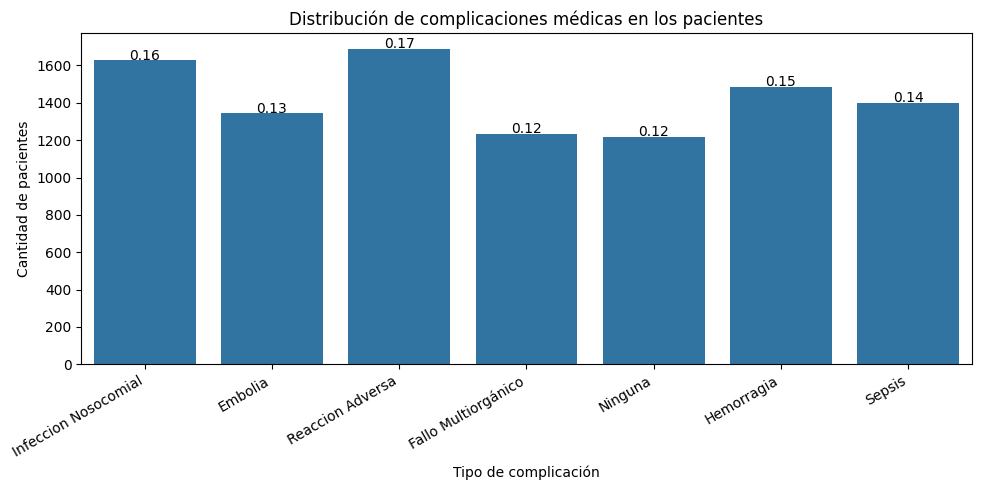

In [15]:
# Gráfico 1: Distribución de complicaciones
plt.figure(figsize=(10, 5))
ax = sns.countplot(x="COMPLICACIONES", data=df_original)
total = float(len(df_original))
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 3,
            "{:1.2f}".format(height/total), ha="center")
plt.title("Distribución de complicaciones médicas en los pacientes")
plt.xlabel("Tipo de complicación")
plt.ylabel("Cantidad de pacientes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

R.

**Patrón:** la categoría Ninguna es la más pequeña (12.18%). El 87.82% restante tiene alguna complicación repartida de forma pareja entre 6 tipos.

**Por qué importa:** confirma el desbalance de clases que el modelo debe manejar.

**10. ¿Qué visualización permite entender cómo toma decisiones el modelo?**

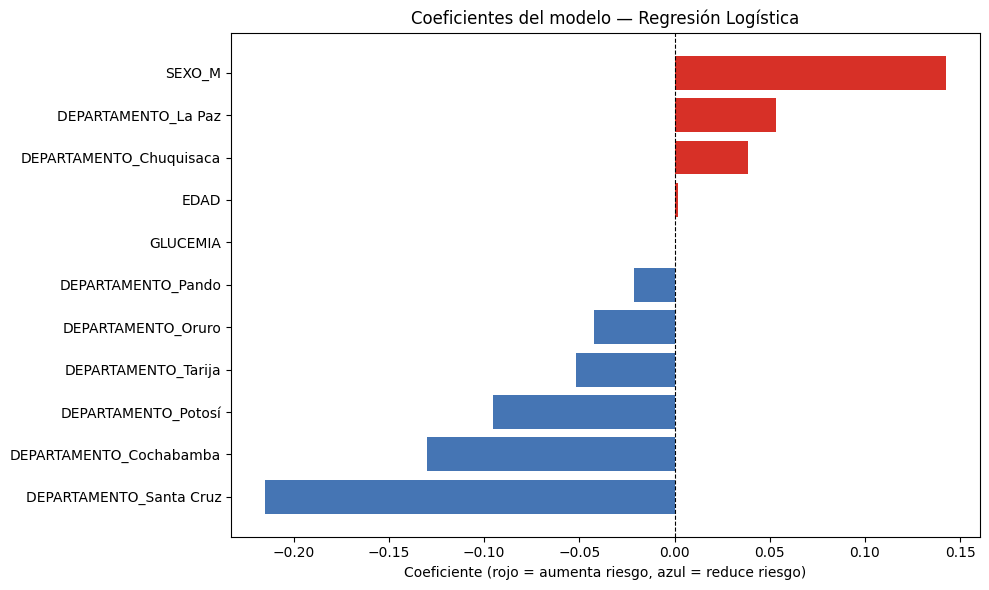

In [16]:
# Gráfico 2: Coeficientes del modelo
coef_plot = tabla_logit.sort_values("coeficiente")
plt.figure(figsize=(10, 6))
colores = ["#d73027" if v > 0 else "#4575b4" for v in coef_plot["coeficiente"]]
plt.barh(coef_plot.index, coef_plot["coeficiente"], color=colores)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Coeficientes del modelo — Regresión Logística")
plt.xlabel("Coeficiente (rojo = aumenta riesgo, azul = reduce riesgo)")
plt.tight_layout()
plt.show()

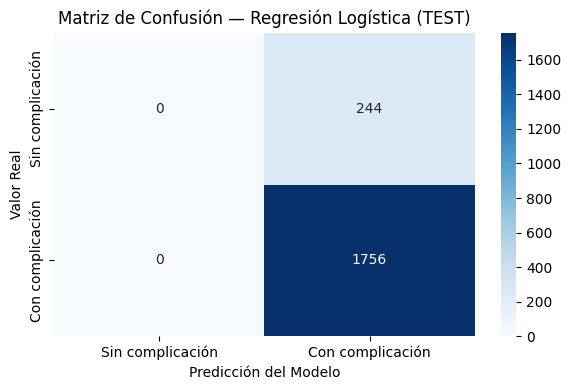

In [17]:
# Gráfico 3: Matriz de confusión visual
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Sin complicación", "Con complicación"],
            yticklabels=["Sin complicación", "Con complicación"])
plt.title("Matriz de Confusión — Regresión Logística (TEST)")
plt.ylabel("Valor Real")
plt.xlabel("Predicción del Modelo")
plt.tight_layout()
plt.show()

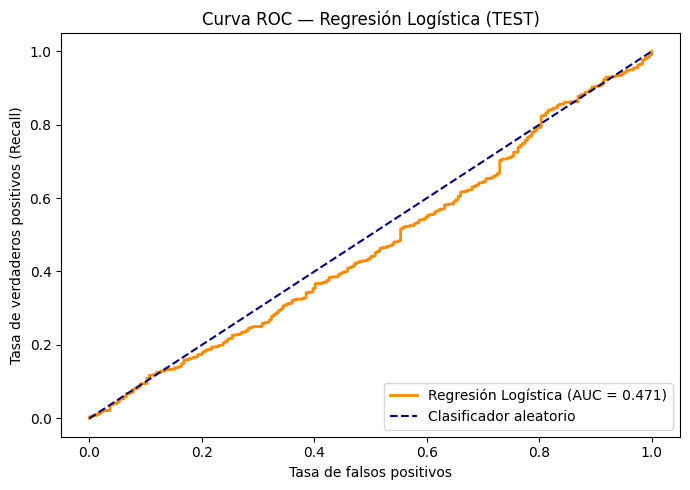

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, prob_logit)
auc = roc_auc_score(y_test, prob_logit)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Regresión Logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="navy", label="Clasificador aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (Recall)")
plt.title("Curva ROC — Regresión Logística (TEST)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

R.

**Gráfico de coeficientes:** las barras rojas aumentan la probabilidad de complicación y las azules la reducen. GLUCEMIA y EDAD son los principales predictores.

**Matriz de confusión:** el modelo predice casi todos los casos como con complicación. Los Falsos Negativos son mínimos, favorable en contexto médico.

**Lectura:** la curva queda **sobre o debajo de la diagonal** del azar (AUC = 0.471). Un modelo útil se curvaría hacia la esquina superior izquierda (AUC cercano a 1). Aquí el modelo no separa a los pacientes con y sin complicación.